# 01 - Data Exploration: Forest Cover Type

**Goal:** Understand the Covertype dataset before building any model.

**Dataset:** UCI Covertype. Each row is a 30m x 30m patch of forest in Colorado, described by cartographic variables (elevation, slope, soil type, etc.). The task is to predict the forest cover type (7 classes).

**Questions for this notebook:**
1. How big is the data and is it clean?
2. Are the classes balanced?
3. Do the numeric features have very different scales?

## 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

The raw file has **no header**, so I define the column names myself, following the UCI documentation:
- 10 numeric features
- 4 binary `Wilderness_Area` columns (one-hot)
- 40 binary `Soil_Type` columns (one-hot)
- 1 target column: `Cover_Type`

In [2]:
numeric_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]
wilderness_cols = [f"Wilderness_Area_{i}" for i in range(1, 5)]
soil_cols = [f"Soil_Type_{i}" for i in range(1, 41)]

col_names = numeric_cols + wilderness_cols + soil_cols + ["Cover_Type"]

In [3]:
len(col_names)

55

In [4]:
df = pd.read_csv("../data/covtype.data.gz", header=None, names=col_names)

## 2. Structure and data quality

In [5]:
df.shape

(581012, 55)

In [6]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Soil_Type_40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area_1                   581012 non-null  int64
 11  Wilderness_Area_2                   581012 non-null  int64
 12 

In [8]:
df.isna().sum().sum()

np.int64(0)

**Observations**
- The data has 581,012 rows and 55 columns (54 features + 1 target).
- All columns are integers (`int64`).
- There are no missing values.

## 3. Target distribution

The target `Cover_Type` has 7 classes, numbered 1 to 7.

In [9]:
df["Cover_Type"].value_counts()

Cover_Type
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

In [10]:
target_percentages = df["Cover_Type"].value_counts(normalize=True)*100
target_percentages

Cover_Type
2    48.759922
1    36.460521
3     6.153746
7     3.530048
6     2.989095
5     1.633873
4     0.472796
Name: proportion, dtype: float64

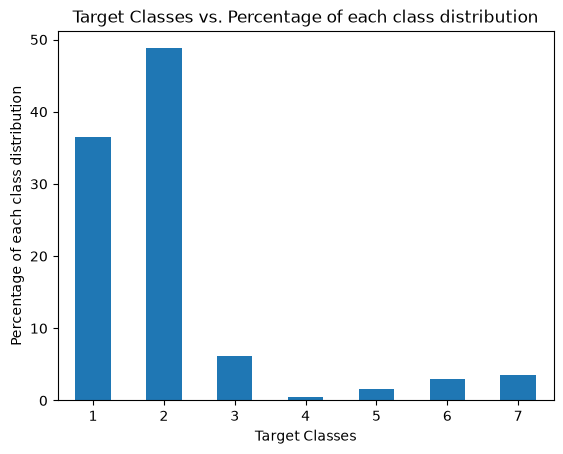

In [11]:
target_percentages.sort_index().plot(kind='bar', rot=0)
plt.title("Target Classes vs. Percentage of each class distribution")
plt.xlabel("Target Classes")
plt.ylabel("Percentage of each class distribution")
plt.savefig("../results/class_distribution.png")

**Observations**
- The dataset is **imbalanced**. Class 2 (48.8%) and class 1 (36.5%) together make up about 85% of the data.
- Class 4 is very rare (0.47%, only 2,747 samples).
- A model that always predicts class 2 would already reach about 49% accuracy, so accuracy alone is not enough.

**Consequences for the next notebooks**
- Use a **stratified** train/dev/test split.
- Report macro F1 and per-class recall, not only accuracy.
- Look at the confusion matrix to see which small classes are ignored.

## 4. Numeric features

Checking the range of the 10 numeric features. The binary columns (wilderness and soil) are not included.

In [12]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


**Observations**
- The scales are very different. `Elevation` is around 1,859 to 3,858, the distance features go up to about 7,000, `Hillshade` is between 0 and 254, and `Slope` has a maximum of 66.
- `Vertical_Distance_To_Hydrology` has negative values (minimum -173). This is valid: it means the water is below that point.
- Because of the different scales, I will **standardize the 10 numeric features** (using statistics from the training set only). The binary columns stay unchanged.

## 5. Summary

| Item | Finding |
|---|---|
| Size | 581,012 samples, 54 features |
| Missing values | None |
| Classes | 7, strongly imbalanced (largest 48.8%, smallest 0.47%) |
| Feature scales | Very different, normalization needed |

**Next:** `02_baselines.ipynb` - label shift (1-7 to 0-6), stratified split, normalization, and baseline models.